In [1]:
from pathlib import Path
import pandas as pd

pasta_dados = Path("../data/raw")

pedidos = pd.read_csv(pasta_dados / "olist_orders_dataset.csv")

print("Quantidade de pedidos:", len(pedidos))
print("Quantidade de colunas:", len(pedidos.columns))

pedidos.head()



ImportError: Unable to import required dependency numpy. Please see the traceback for details.

In [ ]:
print("DIMENSÕES DO ARQUIVO")
print(pedidos.shape)

print("\nNOMES DAS COLUNAS")
print(pedidos.columns.tolist())

print("\nTIPOS DE DADOS")
print(pedidos.dtypes)

print("\nVALORES AUSENTES")
print(pedidos.isnull().sum())


In [ ]:
print("QUANTIDADE DE PEDIDOS POR STATUS")
print(pedidos["order_status"].value_counts())

print("\nVALORES AUSENTES POR STATUS")
print(
    pedidos.groupby("order_status")[
        [
            "order_approved_at",
            "order_delivered_carrier_date",
            "order_delivered_customer_date"
        ]
        .apply(lambda grupo: grupo.isnull().sum())
    ]
)

In [ ]:
print("QUANTIDADE DE PEDIDOS POR STATUS")
print(pedidos["order_status"].value_counts())

print("\nVALORES AUSENTES POR STATUS")
print(
    pedidos.groupby("order_status")[
        [
            "order_approved_at",
            "order_delivered_carrier_date",
            "order_delivered_customer_date"
        ]
        .apply(lambda grupo: grupo.isnull().sum())
    ]
)

In [ ]:
print("QUANTIDADE DE PEDIDOS POR STATUS")
print(pedidos["order_status"].value_counts())

print("\nVALORES AUSENTES POR STATUS")

colunas_datas = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date"
]

print(
    pedidos.groupby("order_status")[colunas_datas]
    .apply(lambda grupo: grupo.isnull().sum())
)

In [ ]:
entregues_sem_data = pedidos[
    (pedidos["order_status"] == "delivered") &
    (
        pedidos["order_delivered_customer_date"].isnull() |
        pedidos["order_approved_at"].isnull()
    )
]

print("Pedidos entregues com alguma data ausente:")
print(len(entregues_sem_data))

display(entregues_sem_data)

In [ ]:
entregues = pedidos[pedidos["order_status"] == "delivered"]

print("Entregues sem data de aprovação:")
print(entregues["order_approved_at"].isnull().sum())

print("\nEntregues sem data de entrega ao cliente:")
print(entregues["order_delivered_customer_date"].isnull().sum())

print("\nEntregues sem data de envio à transportadora:")
print(entregues["order_delivered_carrier_date"].isnull().sum())

print("\nEntregues sem data de aprovação E sem data de entrega:")
print(
    (
        entregues["order_approved_at"].isnull()
        & entregues["order_delivered_customer_date"].isnull()
    ).sum()
)

## Qualidade dos dados — Pedidos entregues

Durante a exploração inicial da base de pedidos, foram identificadas
as seguintes inconsistências entre pedidos com status `delivered`:

- 14 pedidos sem data de aprovação.
- 8 pedidos sem data de entrega ao cliente.
- 2 pedidos sem data de envio à transportadora.

Não houve pedidos com ausência simultânea da data de aprovação e
da data de entrega ao cliente.

Esses registros serão preservados durante a exploração inicial.
As ausências serão consideradas nas análises posteriores, evitando
a exclusão de dados sem justificativa.


In [ ]:
colunas_datas = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for coluna in colunas_datas:
    pedidos[coluna] = pd.to_datetime(
        pedidos[coluna],
        errors="coerce"
    )

print("TIPOS DE DADOS APÓS A CONVERSÃO")
print(pedidos.dtypes)

In [ ]:
from pathlib import Path
import pandas as pd

In [ ]:
pasta_dados = Path("../data/raw")

pedidos = pd.read_csv(
    pasta_dados / "olist_orders_dataset.csv"
)

print("Pedidos carregados:", len(pedidos))

In [ ]:
colunas_datas = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for coluna in colunas_datas:
    pedidos[coluna] = pd.to_datetime(
        pedidos[coluna],
        errors="coerce"
    )

print(pedidos.dtypes)

In [ ]:
print("Tipos das colunas de data:")
print(pedidos[colunas_datas].dtypes)

print("\nQuantidade de valores ausentes após a conversão:")
print(pedidos[colunas_datas].isnull().sum())

In [ ]:
# Selecionar apenas os pedidos entregues
pedidos_entregues = pedidos[
    pedidos["order_status"] == "delivered"
].copy()

# Calcular o tempo entre a compra e a entrega
pedidos_entregues["tempo_entrega_dias"] = (
    pedidos_entregues["order_delivered_customer_date"]
    - pedidos_entregues["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Exibir estatísticas do tempo de entrega
print("ESTATÍSTICAS DO TEMPO DE ENTREGA (DIAS)")
print(
    pedidos_entregues["tempo_entrega_dias"].describe().round(2)
)

In [ ]:
# Calcular a diferença entre a entrega real e a prevista
pedidos_entregues["diferenca_entrega_dias"] = (
    pedidos_entregues["order_delivered_customer_date"]
    - pedidos_entregues["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

# Classificar a pontualidade
pedidos_entregues["situacao_entrega"] = (
    pedidos_entregues["diferenca_entrega_dias"]
    .apply(
        lambda dias: (
            "Atrasado" if dias > 0
            else "No prazo ou antecipado" if pd.notna(dias)
            else "Sem data de entrega"
        )
    )
)

print("SITUAÇÃO DAS ENTREGAS")
print(pedidos_entregues["situacao_entrega"].value_counts())

print("\nPERCENTUAL POR SITUAÇÃO")
print(
    (pedidos_entregues["situacao_entrega"].value_counts(normalize=True) * 100)
    .round(2)
)

## Análise de pontualidade das entregas

Foram analisados 96.478 pedidos com status `delivered`.

Resultados:
- 88.644 entregas no prazo ou antecipadas (91,88% do total).
- 7.826 entregas atrasadas (8,11% do total).
- 8 pedidos sem data de entrega ao cliente (0,01% do total).

Considerando apenas os pedidos com data real de entrega disponível,
91,89% chegaram no prazo ou antes dele.

O indicador foi calculado comparando a data de entrega ao cliente
com a data estimada de entrega. Valores positivos representam
atrasos; valores negativos representam entregas antecipadas.


# Analisar somente pedidos entregues
pedidos_entregues = pedidos[
    pedidos["order_status"] == "delivered"
].copy()

# Calcular os dias de atraso
pedidos_entregues["dias_atraso"] = (
    pedidos_entregues["order_delivered_customer_date"]
    - pedidos_entregues["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

# Considerar apenas pedidos com data real de entrega
atrasos = pedidos_entregues[
    pedidos_entregues["dias_atraso"].notna()
    & (pedidos_entregues["dias_atraso"] > 0)
]

print("Quantidade de pedidos atrasados:", len(atrasos))
print("\nEstatísticas dos dias de atraso:")
print(atrasos["dias_atraso"].describe().round(2))

In [ ]:
### Análise dos dias de atraso

Foram identificados **7.826 pedidos entregues após a data estimada**.

Principais resultados:
- Atraso médio: 9,55 dias.
- Atraso mediano: 5,81 dias.
- 25% dos pedidos atrasados tiveram atraso de até 1,87 dia.
- 75% tiveram atraso de até 11,82 dias.
- O maior atraso registrado foi de aproximadamente 189 dias.

A média superior à mediana sugere a presença de atrasos extremos que elevam o tempo médio. Esses casos podem ser investigados posteriormente para entender melhor os problemas de entrega.

**Observação:** esta análise considera apenas pedidos entregues com data real de entrega disponível e atraso superior a zero.

### Análise dos dias de atraso

Foram identificados **7.826 pedidos entregues após a data estimada**.

Principais resultados:
- Atraso médio: 9,55 dias.
- Atraso mediano: 5,81 dias.
- 25% dos pedidos atrasados tiveram atraso de até 1,87 dia.
- 75% tiveram atraso de até 11,82 dias.
- O maior atraso registrado foi de aproximadamente 189 dias.

A média superior à mediana sugere a presença de atrasos extremos que elevam o tempo médio. Esses casos podem ser investigados posteriormente para entender melhor os problemas de entrega.

**Observação:** esta análise considera apenas pedidos entregues com data real de entrega disponível e atraso superior a zero.

In [ ]:
# Carregar a tabela de clientes
clientes = pd.read_csv(
    pasta_dados / "olist_customers_dataset.csv"
)

# Conferir as primeiras linhas
clientes.head()

In [ ]:
# Verificar quantos clientes existem por estado
clientes["customer_state"].value_counts()

In [ ]:
# Juntar pedidos com os dados dos clientes
pedidos_com_estado = pedidos.merge(
    clientes[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)

# Conferir o resultado
print("Total de pedidos:", len(pedidos_com_estado))
print("\nPedidos sem estado identificado:",
      pedidos_com_estado["customer_state"].isna().sum())

pedidos_com_estado[
    ["order_id", "customer_id", "customer_state"]
].head()

In [ ]:
# Manter somente pedidos entregues
entregues_estado = pedidos_com_estado[
    pedidos_com_estado["order_status"] == "delivered"
].copy()

# Calcular os dias de atraso em relação à data estimada
entregues_estado["dias_atraso"] = (
    entregues_estado["order_delivered_customer_date"]
    - entregues_estado["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

# Criar indicador de atraso
entregues_estado["atrasado"] = (
    entregues_estado["dias_atraso"] > 0
)

# Resumir os resultados por estado
atrasos_por_estado = (
    entregues_estado
    .groupby("customer_state")
    .agg(
        total_pedidos=("order_id", "count"),
        pedidos_com_data=("dias_atraso", "count"),
        pedidos_atrasados=("atrasado", "sum"),
        media_atraso_dias=("dias_atraso", "mean")
    )
)

# Calcular o percentual de pedidos atrasados
atrasos_por_estado["percentual_atraso"] = (
    atrasos_por_estado["pedidos_atrasados"]
    / atrasos_por_estado["pedidos_com_data"]
    * 100
)

# Mostrar os 10 estados com maior percentual de atraso
atrasos_por_estado.sort_values(
    "percentual_atraso",
    ascending=False
).head(10).round(2)

In [ ]:
### Análise de atrasos por estado

A análise identificou diferenças no percentual de atrasos entre os estados brasileiros.

Principais resultados entre os dez estados apresentados:
- Alagoas apresentou o maior percentual de atrasos, com 23,93%.
- Maranhão registrou 19,67%.
- Piauí registrou 15,97%.
- Bahia apresentou 14,04%, com 457 pedidos atrasados entre 3.256 pedidos com data de entrega disponível.

Os resultados indicam que o percentual de atrasos varia geograficamente. Entretanto, estados com menor quantidade de pedidos devem ser analisados com cautela, pois amostras menores podem apresentar maior variação.

**Metodologia:** percentual de atraso calculado dividindo a quantidade de pedidos atrasados pela quantidade de pedidos com data real de entrega disponível, por estado.

### Análise de atrasos por estado

A análise identificou diferenças no percentual de atrasos entre os estados brasileiros.

Principais resultados entre os dez estados apresentados:
- Alagoas apresentou o maior percentual de atrasos, com 23,93%.
- Maranhão registrou 19,67%.
- Piauí registrou 15,97%.
- Bahia apresentou 14,04%, com 457 pedidos atrasados entre 3.256 pedidos com data de entrega disponível.

Os resultados indicam que o percentual de atrasos varia geograficamente. Entretanto, estados com menor quantidade de pedidos devem ser analisados com cautela, pois amostras menores podem apresentar maior variação.

**Metodologia:** percentual de atraso calculado dividindo a quantidade de pedidos atrasados pela quantidade de pedidos com data real de entrega disponível, por estado.

In [ ]:
import matplotlib.pyplot as plt

# Ordenar os estados pelo percentual de atraso
dados_grafico = atrasos_por_estado.sort_values(
    "percentual_atraso",
    ascending=False
)

# Criar o gráfico
plt.figure(figsize=(12, 6))

plt.bar(
    dados_grafico.index,
    dados_grafico["percentual_atraso"]
)

plt.title("Percentual de pedidos atrasados por estado")
plt.xlabel("Estado")
plt.ylabel("Pedidos atrasados (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [ ]:
# Ordenar os estados pela quantidade de pedidos atrasados
dados_volume = atrasos_por_estado.sort_values(
    "pedidos_atrasados",
    ascending=False
)

# Selecionar os 10 estados com mais atrasos
top_10_atrasos = dados_volume.head(10)

# Criar o gráfico
plt.figure(figsize=(12, 6))

plt.bar(
    top_10_atrasos.index,
    top_10_atrasos["pedidos_atrasados"]
)

plt.title("10 estados com maior quantidade de pedidos atrasados")
plt.xlabel("Estado")
plt.ylabel("Quantidade de pedidos atrasados")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Comparação entre percentual e volume de atrasos

Foram construídos dois gráficos para analisar os atrasos nas entregas por estado:

1. **Percentual de atrasos:** permite identificar os estados em que uma proporção maior dos pedidos entregues chegou depois da data estimada.
2. **Quantidade de pedidos atrasados:** permite identificar os estados que concentram o maior número absoluto de entregas atrasadas.

A análise conjunta dos dois indicadores é importante porque um estado pode apresentar uma taxa elevada de atrasos, mesmo com um volume pequeno de pedidos. Da mesma forma, estados com maior volume de pedidos podem concentrar mais atrasos em números absolutos, mesmo com uma taxa percentual menor.

Essa comparação pode ajudar a priorizar investigações sobre o desempenho logístico.

In [ ]:
# Carregar a tabela de pagamentos
pagamentos = pd.read_csv(
    pasta_dados / "olist_order_payments_dataset.csv"
)

# Visualizar as primeiras linhas
pagamentos.head()

In [ ]:
# Verificar o tamanho da tabela
print("Quantidade de registros:", len(pagamentos))
print("Quantidade de pedidos únicos:", pagamentos["order_id"].nunique())

# Verificar valores ausentes
print("\nValores ausentes:")
print(pagamentos.isna().sum())

# Resumo dos valores pagos
print("\nResumo dos valores de pagamento:")
print(pagamentos["payment_value"].describe().round(2))

# Somar todos os pagamentos de cada pedido
valor_por_pedido = (
    pagamentos
    .groupby("order_id", as_index=False)
    .agg(valor_total_pedido=("payment_value", "sum"))
)

# Calcular indicadores financeiros
print("Total de pedidos com pagamento:", len(valor_por_pedido))

print(
    "Valor total dos pagamentos: R$",
    round(valor_por_pedido["valor_total_pedido"].sum(), 2)
)

print(
    "Ticket médio por pedido: R$",
    round(valor_por_pedido["valor_total_pedido"].mean(), 2)
)

print(
    "Mediana do valor por pedido: R$",
    round(valor_por_pedido["valor_total_pedido"].median(), 2)
)

In [ ]:
### Análise financeira dos pedidos

A tabela de pagamentos apresentou os seguintes resultados:

- Total dos pagamentos registrados: R$ 16.008.872,12.
- Pedidos únicos com registro de pagamento: 99.440.
- Ticket médio por pedido: R$ 160,99.
- Mediana do valor por pedido: R$ 105,29.

O ticket médio foi superior à mediana, indicando que pedidos de maior valor podem estar influenciando a média.

Para calcular o valor por pedido, os registros de pagamento foram agrupados pelo identificador `order_id`, somando-se os valores associados a cada pedido antes do cálculo dos indicadores.

**Limitação:** esses valores representam os pagamentos registrados na base. A análise ainda não distingue pedidos entregues, cancelados ou com outros status.

### Análise financeira dos pedidos

A tabela de pagamentos apresentou os seguintes resultados:

- Total dos pagamentos registrados: R$ 16.008.872,12.
- Pedidos únicos com registro de pagamento: 99.440.
- Ticket médio por pedido: R$ 160,99.
- Mediana do valor por pedido: R$ 105,29.

O ticket médio foi superior à mediana, indicando que pedidos de maior valor podem estar influenciando a média.

Para calcular o valor por pedido, os registros de pagamento foram agrupados pelo identificador `order_id`, somando-se os valores associados a cada pedido antes do cálculo dos indicadores.

**Limitação:** esses valores representam os pagamentos registrados na base. A análise ainda não distingue pedidos entregues, cancelados ou com outros status.

In [ ]:
### Análise financeira dos pedidos

A tabela de pagamentos apresentou os seguintes resultados:

- Total dos pagamentos registrados: R$ 16.008.872,12.
- Pedidos únicos com registro de pagamento: 99.440.
- Ticket médio por pedido: R$ 160,99.
- Mediana do valor por pedido: R$ 105,29.

O ticket médio foi superior à mediana, indicando que pedidos de maior valor podem estar influenciando a média.

Para calcular o valor por pedido, os registros de pagamento foram agrupados pelo identificador `order_id`, somando-se os valores associados a cada pedido antes do cálculo dos indicadores.

**Limitação:** esses valores representam os pagamentos registrados na base. A análise ainda não distingue pedidos entregues, cancelados ou com outros status.

### Análise financeira dos pedidos

A tabela de pagamentos apresentou os seguintes resultados:

- Total dos pagamentos registrados: R$ 16.008.872,12.
- Pedidos únicos com registro de pagamento: 99.440.
- Ticket médio por pedido: R$ 160,99.
- Mediana do valor por pedido: R$ 105,29.

O ticket médio foi superior à mediana, indicando que pedidos de maior valor podem estar influenciando a média.

Para calcular o valor por pedido, os registros de pagamento foram agrupados pelo identificador `order_id`, somando-se os valores associados a cada pedido antes do cálculo dos indicadores.

**Limitação:** esses valores representam os pagamentos registrados na base. A análise ainda não distingue pedidos entregues, cancelados ou com outros status.

In [ ]:
pagamentos.head()

In [ ]:
pagamentos.head()

In [2]:
pagamentos.head()

NameError: name 'pagamentos' is not defined

In [1]:
import pandas as pd
import numpy as np

print("Ambiente funcionando!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)


Ambiente funcionando!
Pandas: 3.1.0
NumPy: 2.5.4


In [2]:
from pathlib import Path
import pandas as pd

pasta_dados = Path("../data/raw")

pagamentos = pd.read_csv(
    pasta_dados / "olist_order_payments_dataset.csv"
)

pagamentos.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [3]:
pagamentos["payment_type"].value_counts()

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

In [4]:
quantidade_pagamentos = pagamentos["payment_type"].value_counts()

percentual_pagamentos = (
    quantidade_pagamentos / quantidade_pagamentos.sum() * 100
).round(2)

resumo_metodos_pagamento = pd.DataFrame({
    "quantidade": quantidade_pagamentos,
    "percentual": percentual_pagamentos
})

resumo_metodos_pagamento

,quantidade,percentual
payment_type,,
credit_card,76795,73.92
boleto,19784,19.04
voucher,5775,5.56
debit_card,1529,1.47
not_defined,3,0.00


In [1]:
import matplotlib.pyplot as plt

dados_grafico = resumo_metodos_pagamento.sort_values(
    "percentual", ascending=False
)

plt.figure(figsize=(10, 6))
plt.bar(dados_grafico.index, dados_grafico["percentual"])
plt.title("Distribuição dos métodos de pagamento")
plt.xlabel("Método de pagamento")
plt.ylabel("Percentual dos registros (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

NameError: name 'resumo_metodos_pagamento' is not defined

In [2]:
import pandas as pd
from pathlib import Path

pasta_dados = Path("../data/raw")

pagamentos = pd.read_csv(
    pasta_dados / "olist_order_payments_dataset.csv"
)

quantidade_pagamentos = pagamentos["payment_type"].value_counts()

percentual_pagamentos = (
    quantidade_pagamentos / quantidade_pagamentos.sum() * 100
).round(2)

resumo_metodos_pagamento = pd.DataFrame({
    "quantidade": quantidade_pagamentos,
    "percentual": percentual_pagamentos
})

resumo_metodos_pagamento

,quantidade,percentual
payment_type,,
credit_card,76795,73.92
boleto,19784,19.04
voucher,5775,5.56
debit_card,1529,1.47
not_defined,3,0.00


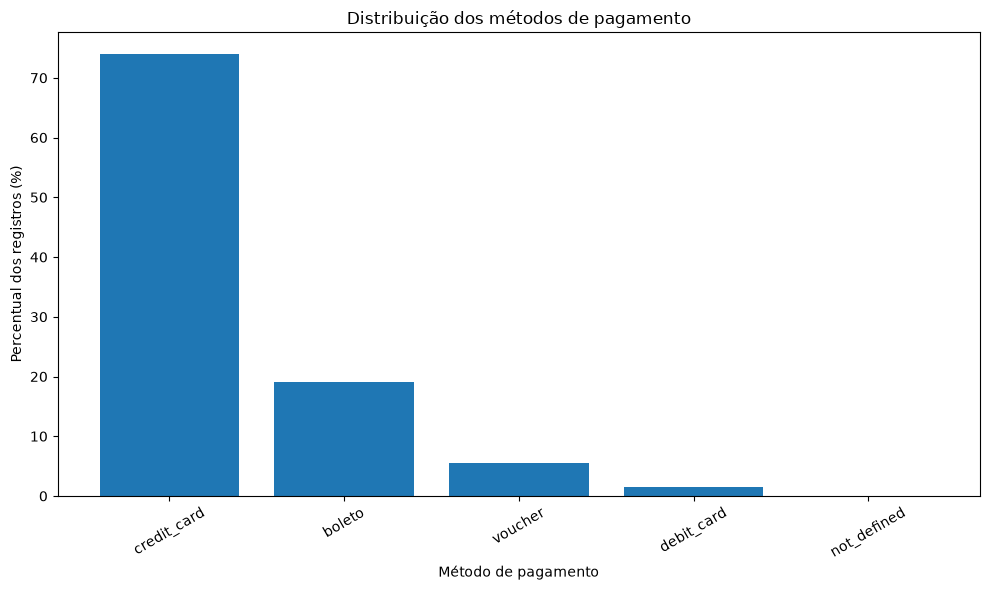

In [3]:
import matplotlib.pyplot as plt

dados_grafico = resumo_metodos_pagamento.sort_values(
    "percentual", ascending=False
)

plt.figure(figsize=(10, 6))
plt.bar(dados_grafico.index, dados_grafico["percentual"])

plt.title("Distribuição dos métodos de pagamento")
plt.xlabel("Método de pagamento")
plt.ylabel("Percentual dos registros (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

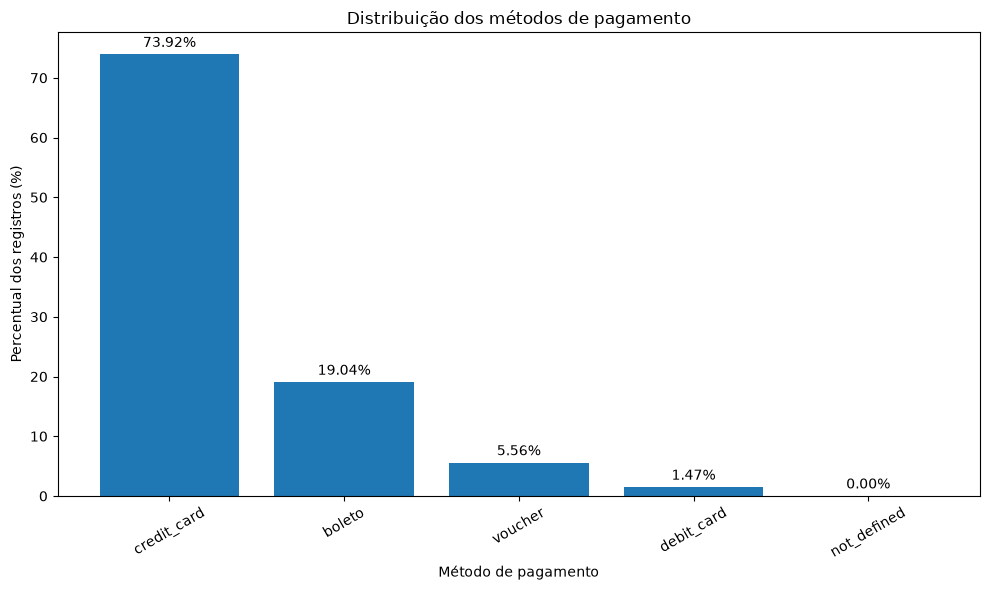

In [4]:
import matplotlib.pyplot as plt

dados_grafico = resumo_metodos_pagamento.sort_values(
    "percentual", ascending=False
)

plt.figure(figsize=(10, 6))
barras = plt.bar(
    dados_grafico.index,
    dados_grafico["percentual"]
)

plt.bar_label(
    barras,
    labels=[f"{valor:.2f}%" for valor in dados_grafico["percentual"]],
    padding=3
)

plt.title("Distribuição dos métodos de pagamento")
plt.xlabel("Método de pagamento")
plt.ylabel("Percentual dos registros (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Análise dos métodos de pagamento

A análise dos 103.886 registros de pagamento mostrou uma predominância do cartão de crédito, responsável por 73,92% dos registros. O boleto aparece em segundo lugar, com 19,04%, seguido pelo voucher, com 5,56%, e pelo cartão de débito, com 1,47%.

Foram identificados ainda 3 registros com método de pagamento não definido, representando aproximadamente 0,003% do total, ou 0,00% após arredondamento para duas casas decimais.

**Principais conclusões:**
- O cartão de crédito é o método de pagamento predominante na base analisada.
- O boleto ocupa a segunda posição, com participação consideravelmente menor.
- Voucher e cartão de débito representam parcelas pequenas dos registros.
- Existem poucos registros sem método de pagamento definido.

**Observação metodológica:** os percentuais foram calculados sobre os 103.886 registros da tabela de pagamentos, e não sobre a quantidade de pedidos únicos. Um mesmo pedido pode apresentar mais de um registro de pagamento.

In [5]:
parcelamentos = (
    pagamentos[pagamentos["payment_type"] == "credit_card"]
    ["payment_installments"]
    .value_counts()
    .sort_index()
)

parcelamentos

payment_installments
0         2
1     25455
2     12413
3     10461
4      7098
5      5239
6      3920
7      1626
8      4268
9       644
10     5328
11       23
12      133
13       16
14       15
15       74
16        5
17        8
18       27
20       17
21        3
22        1
23        1
24       18
Name: count, dtype: int64

In [6]:
parcelamentos = (
    pagamentos[pagamentos["payment_type"] == "credit_card"]
    ["payment_installments"]
    .value_counts()
    .sort_index()
)

resumo_parcelamentos = pd.DataFrame({
    "quantidade": parcelamentos,
    "percentual": (parcelamentos / parcelamentos.sum() * 100).round(2)
})

resumo_parcelamentos

,quantidade,percentual
payment_installments,,
0,2,0.00
1,25455,33.15
2,12413,16.16
3,10461,13.62
4,7098,9.24
5,5239,6.82
6,3920,5.10
7,1626,2.12
8,4268,5.56


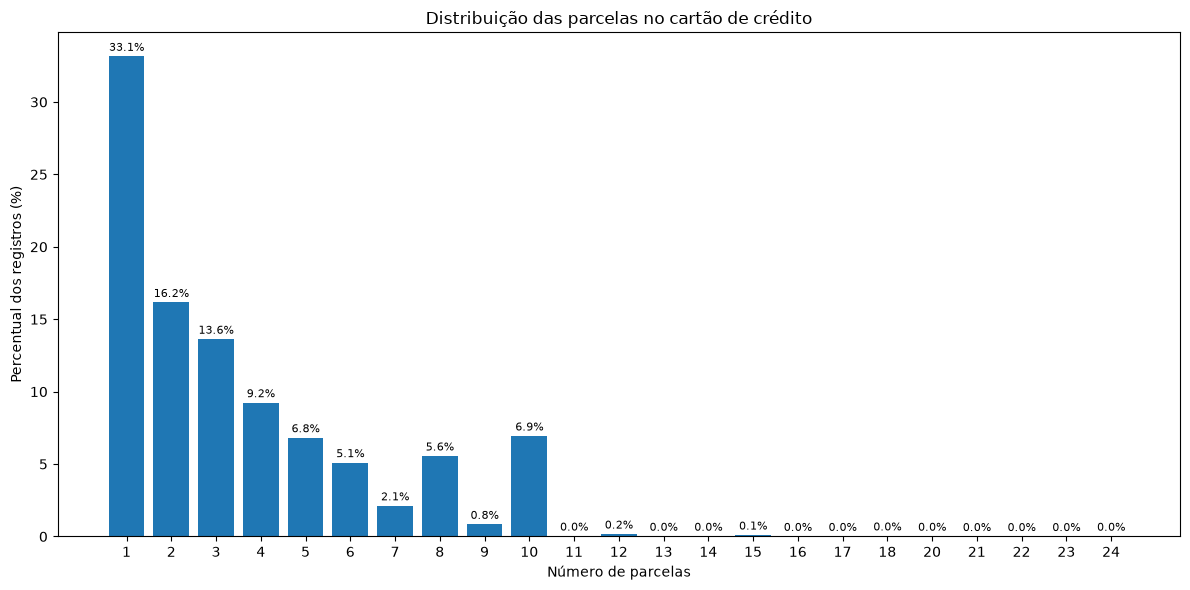

In [7]:
import matplotlib.pyplot as plt

dados_parcelamento = resumo_parcelamentos.loc[
    resumo_parcelamentos.index > 0
]

plt.figure(figsize=(12, 6))

barras = plt.bar(
    dados_parcelamento.index.astype(str),
    dados_parcelamento["percentual"]
)

plt.bar_label(
    barras,
    labels=[
        f"{valor:.1f}%" for valor in dados_parcelamento["percentual"]
    ],
    padding=2,
    fontsize=8
)

plt.title("Distribuição das parcelas no cartão de crédito")
plt.xlabel("Número de parcelas")
plt.ylabel("Percentual dos registros (%)")
plt.tight_layout()
plt.show()

### Análise do parcelamento no cartão de crédito

- **1 parcela:** 33,15% dos registros de pagamento com cartão.
- **2 parcelas:** 16,16%.
- **3 parcelas:** 13,62%.
- **4 parcelas:** 9,24%.
- **10 parcelas:** 6,94%.
- **Parcelamentos mais longos:** as frequências diminuem, em geral, conforme aumenta o número de parcelas.

**Principais conclusões:**

1. O pagamento em uma única parcela é a opção mais frequente.
2. Parcelamentos de 2 e 3 vezes também apresentam participação relevante.
3. Existem registros com até 24 parcelas, mas eles representam uma parcela pequena do total.
4. Foram encontrados 2 registros com zero parcelas, uma possível inconsistência que merece ser investigada.

**Observação metodológica:** os percentuais consideram os registros de pagamento feitos com cartão de crédito, e não necessariamente pedidos únicos. Portanto, os resultados descrevem a distribuição dos registros, não o comportamento individual de cada cliente.

In [8]:
import pandas as pd
from pathlib import Path

pasta_dados = Path("../data/raw")

avaliacoes = pd.read_csv(
    pasta_dados / "olist_order_reviews_dataset.csv"
)

avaliacoes.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [9]:
notas = avaliacoes["review_score"].value_counts().sort_index()

resumo_notas = pd.DataFrame({
    "quantidade": notas,
    "percentual": (notas / notas.sum() * 100).round(2)
})

resumo_notas

,quantidade,percentual
review_score,,
1,11424,11.51
2,3151,3.18
3,8179,8.24
4,19142,19.29
5,57328,57.78


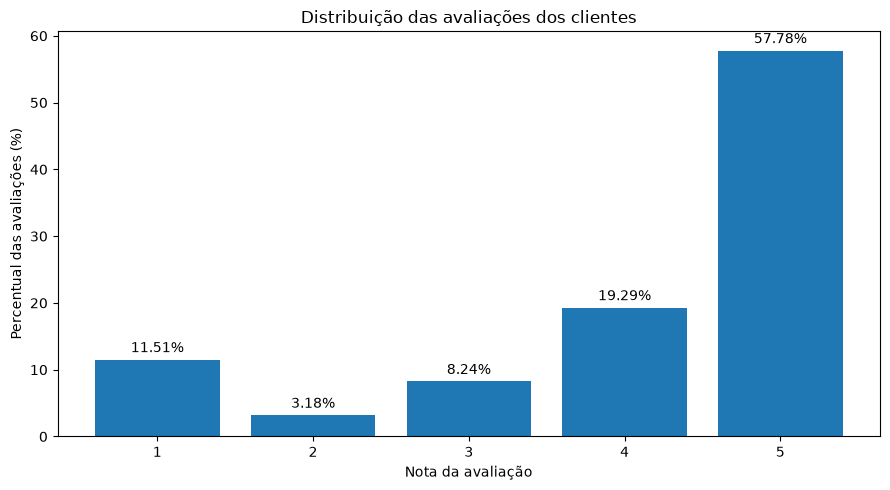

In [10]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

barras = plt.bar(
    resumo_notas.index.astype(str),
    resumo_notas["percentual"]
)

plt.bar_label(
    barras,
    labels=[f"{valor:.2f}%" for valor in resumo_notas["percentual"]],
    padding=3
)

plt.title("Distribuição das avaliações dos clientes")
plt.xlabel("Nota da avaliação")
plt.ylabel("Percentual das avaliações (%)")
plt.tight_layout()
plt.show()


### Análise das avaliações dos clientes

A base apresenta 99.224 avaliações, distribuídas entre notas de 1 a 5.

- **Nota 5:** 57,78% das avaliações.
- **Nota 4:** 19,29%.
- **Nota 3:** 8,24%.
- **Nota 2:** 3,18%.
- **Nota 1:** 11,51%.

**Principais conclusões:**

1. A nota 5 é a mais frequente, representando mais da metade das avaliações.
2. Somando as notas 4 e 5, temos **77,07% de avaliações positivas**.
3. As notas 1 e 2 representam **14,69%**, indicando uma parcela relevante de clientes insatisfeitos.
4. É importante investigar os motivos das notas baixas, especialmente possíveis problemas de entrega, qualidade dos produtos ou atendimento.

**Observação metodológica:** as notas indicam a percepção dos clientes que avaliaram suas compras, mas não necessariamente representam a opinião de todos os compradores. As causas da insatisfação precisam ser investigadas antes de se estabelecer conclusões.

In [11]:

avaliacoes_negativas = avaliacoes[
    avaliacoes["review_score"] <= 2
]

avaliacoes_negativas[
    ["review_score", "review_comment_message"]
].head(10)


,review_score,review_comment_message
5,1,NaN
16,2,"GOSTARIA DE SABER O QUE HOUVE, SEMPRE RECEBI E..."
19,1,Péssimo
29,1,Não gostei ! Comprei gato por lebre
32,1,Sempre compro pela Internet e a entrega ocorre...
39,1,Nada de chegar o meu pedido.
40,2,NaN
41,1,NaN
51,1,recebi somente 1 controle Midea Split ESTILO.\...
68,1,O produto não chegou no prazo estipulado e cau...


In [12]:

total_negativas = len(avaliacoes_negativas)

comentarios_preenchidos = avaliacoes_negativas[
    avaliacoes_negativas["review_comment_message"].notna()
    & (
        avaliacoes_negativas["review_comment_message"]
        .str.strip()
        .ne("")
    )
]

print("Total de avaliações negativas:", total_negativas)
print("Avaliações negativas com comentário:", len(comentarios_preenchidos))
print(
    "Percentual com comentário:",
    round(len(comentarios_preenchidos) / total_negativas * 100, 2),
    "%"
)


Total de avaliações negativas: 14575
Avaliações negativas com comentário: 10889
Percentual com comentário: 74.71 %


In [13]:

from collections import Counter
import re

texto_negativo = " ".join(
    comentarios_preenchidos["review_comment_message"]
    .astype(str)
    .str.lower()
)

palavras = re.findall(r"\b[a-záàâãéêíóôõúç]{3,}\b", texto_negativo)

palavras_comuns = Counter(palavras).most_common(20)

pd.DataFrame(
    palavras_comuns,
    columns=["palavra", "frequencia"]
)


,palavra,frequencia
0,não,7483
1,produto,6189
2,que,3978
3,recebi,3272
4,com,2352
5,foi,1963
6,comprei,1882
7,para,1641
8,veio,1552
9,uma,1545


In [14]:

palavras_ignoradas = {
    "não", "nao", "que", "com", "para", "uma", "foi",
    "meu", "minha", "mas", "até", "estou", "por",
    "dos", "das", "nos", "nas", "tem", "ter", "era",
    "ele", "ela", "seu", "sua", "como", "mais",
    "muito", "muita", "pelo", "pela", "isso", "essa",
    "esse", "quando", "porque", "pois", "já", "só",
    "ao", "os", "as", "de", "do", "da", "em", "no",
    "na", "um", "uns", "umas", "ou", "e", "a", "o"
}

palavras_filtradas = [
    palavra for palavra in palavras
    if palavra not in palavras_ignoradas
]

frequencia_filtrada = Counter(palavras_filtradas).most_common(20)

pd.DataFrame(
    frequencia_filtrada,
    columns=["palavra", "frequencia"]
)


,palavra,frequencia
0,produto,6189
1,recebi,3272
2,comprei,1882
3,veio,1552
4,entrega,1412
5,ainda,1401
6,entregue,1329
7,chegou,1180
8,prazo,916
9,compra,909


In [15]:

termos_entrega = [
    "entrega", "entregue", "atraso", "atrasado",
    "prazo", "chegou", "chegar", "recebi",
    "receber", "correios", "transportadora"
]

comentarios = (
    comentarios_preenchidos["review_comment_message"]
    .astype(str)
    .str.lower()
)

for termo in termos_entrega:
    quantidade = comentarios.str.contains(
        rf"\b{termo}\b", regex=True, na=False
    ).sum()
    print(f"{termo}: {quantidade}")


entrega: 1310
entregue: 1242
atraso: 175
atrasado: 28
prazo: 859
chegou: 1111
chegar: 182
recebi: 3017
receber: 315
correios: 331
transportadora: 46


In [16]:

termos_entrega_regex = (
    r"\b(entrega|entregue|atraso|atrasado|prazo|"
    r"chegou|chegar|recebi|receber|correios|transportadora)\b"
)

menciona_entrega = comentarios.str.contains(
    termos_entrega_regex,
    regex=True,
    na=False
)

quantidade_comentarios_entrega = menciona_entrega.sum()
total_com_comentario = len(comentarios)

percentual_entrega = (
    quantidade_comentarios_entrega / total_com_comentario * 100
)

print("Comentários negativos com menção à entrega:",
      quantidade_comentarios_entrega)
print("Total de comentários negativos com texto:",
      total_com_comentario)
print("Percentual com menção à entrega:",
      round(percentual_entrega, 2), "%")


Comentários negativos com menção à entrega: 6415
Total de comentários negativos com texto: 10889
Percentual com menção à entrega: 58.91 %


C:\Users\João Vitor\AppData\Local\Temp\ipykernel_26380\2445703547.py:6: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  menciona_entrega = comentarios.str.contains(


In [17]:

termos_entrega_regex = (
    r"\b(?:entrega|entregue|atraso|atrasado|prazo|"
    r"chegou|chegar|recebi|receber|correios|transportadora)\b"
)

menciona_entrega = comentarios.str.contains(
    termos_entrega_regex,
    regex=True,
    na=False
)

quantidade_comentarios_entrega = menciona_entrega.sum()

percentual_entrega = (
    quantidade_comentarios_entrega / len(comentarios) * 100
)

print("Comentários com menção à entrega:",
      quantidade_comentarios_entrega)
print("Percentual:",
      round(percentual_entrega, 2), "%")


Comentários com menção à entrega: 6415
Percentual: 58.91 %


### Análise textual das avaliações negativas

Foram identificadas **14.575 avaliações negativas**, das quais **10.889 continham comentários escritos**.

A análise exploratória desses comentários revelou que:

- **6.415 comentários (58,91%)** mencionam pelo menos um termo relacionado à entrega, ao recebimento ou ao prazo.
- Os termos mais frequentes incluem “recebi”, “entrega”, “chegou” e “prazo”.
- As menções indicam que a experiência logística merece investigação mais aprofundada.

**Conclusão:** a entrega é

In [18]:

from pathlib import Path
import pandas as pd

pasta_dados = Path("../data/raw")

pedidos = pd.read_csv(
    pasta_dados / "olist_orders_dataset.csv"
)

colunas_entrega = [
    "order_id",
    "order_status",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

pedidos[colunas_entrega].head()


,order_id,order_status,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,2018-02-16 18:17:02,2018-02-26 00:00:00


In [19]:

pedidos["order_delivered_customer_date"] = pd.to_datetime(
    pedidos["order_delivered_customer_date"]
)

pedidos["order_estimated_delivery_date"] = pd.to_datetime(
    pedidos["order_estimated_delivery_date"]
)

pedidos_entregues = pedidos[
    pedidos["order_status"] == "delivered"
].copy()

pedidos_entregues["dias_atraso"] = (
    pedidos_entregues["order_delivered_customer_date"]
    - pedidos_entregues["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

pedidos_entregues[
    ["order_id", "dias_atraso"]
].head(10)


,order_id,dias_atraso
0,e481f51cbdc54678b7cc49136f2d6af7,-7.107488
1,53cdb2fc8bc7dce0b6741e2150273451,-5.355729
2,47770eb9100c2d0c44946d9cf07ec65d,-17.245498
3,949d5b44dbf5de918fe9c16f97b45f8a,-12.980069
4,ad21c59c0840e6cb83a9ceb5573f8159,-9.238171
5,a4591c265e18cb1dcee52889e2d8acc3,-5.543113
7,6514b8ad8028c9f2cc2374ded245783f,-11.461215
8,76c6e866289321a7c93b82b54852dc33,-31.410995
9,e69bfb5eb88e0ed6a785585b27e16dbf,-6.281597
10,e6ce16cb79ec1d90b1da9085a6118aeb,-8.528808


In [20]:

pedidos_com_notas = pedidos_entregues.merge(
    avaliacoes[["order_id", "review_score"]],
    on="order_id",
    how="inner"
)

pedidos_com_notas[
    ["order_id", "dias_atraso", "review_score"]
].head(10)


,order_id,dias_atraso,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,-7.107488,4
1,53cdb2fc8bc7dce0b6741e2150273451,-5.355729,4
2,47770eb9100c2d0c44946d9cf07ec65d,-17.245498,5
3,949d5b44dbf5de918fe9c16f97b45f8a,-12.980069,5
4,ad21c59c0840e6cb83a9ceb5573f8159,-9.238171,5
5,a4591c265e18cb1dcee52889e2d8acc3,-5.543113,4
6,6514b8ad8028c9f2cc2374ded245783f,-11.461215,5
7,76c6e866289321a7c93b82b54852dc33,-31.410995,1
8,e69bfb5eb88e0ed6a785585b27e16dbf,-6.281597,5
9,e6ce16cb79ec1d90b1da9085a6118aeb,-8.528808,1


In [21]:

pedidos_com_notas["situacao_entrega"] = pedidos_com_notas[
    "dias_atraso"
].apply(
    lambda dias: "Atrasado" if dias > 0 else "No prazo/antecipado"
)

resumo_atraso_notas = (
    pedidos_com_notas
    .groupby("situacao_entrega")
    .agg(
        quantidade_pedidos=("order_id", "count"),
        nota_media=("review_score", "mean"),
        percentual_notas_1_2=(
            "review_score",
            lambda notas: (notas <= 2).mean() * 100
        )
    )
    .round(2)
)

resumo_atraso_notas


,quantidade_pedidos,nota_media,percentual_notas_1_2
situacao_entrega,,,
Atrasado,7700,2.57,54.03
No prazo/antecipado,88661,4.29,9.23


### Relação entre atraso na entrega e satisfação dos clientes

O cruzamento entre os pedidos entregues e as avaliações dos clientes revelou uma diferença importante na satisfação conforme a pontualidade da entrega.

**Resultados principais:**

- Pedidos atrasados: nota média de 2,57 e 54,03% de avaliações negativas.
- Pedidos entregues no prazo ou antecipadamente: nota média de 4,29 e 9,23% de avaliações negativas.
- A proporção de avaliações negativas foi aproximadamente 5,9 vezes maior entre os pedidos atrasados.

**Conclusão:** os resultados indicam uma forte associação entre atrasos na entrega e menor satisfação dos clientes. A pontualidade logística pode ser um indicador relevante para o acompanhamento da experiência de compra.

**Limitação:** a análise é observacional e não demonstra causalidade. Outros fatores, como qualidade do produto, atendimento e divergências entre o produto anunciado e o recebido, também podem influenciar as avaliações.

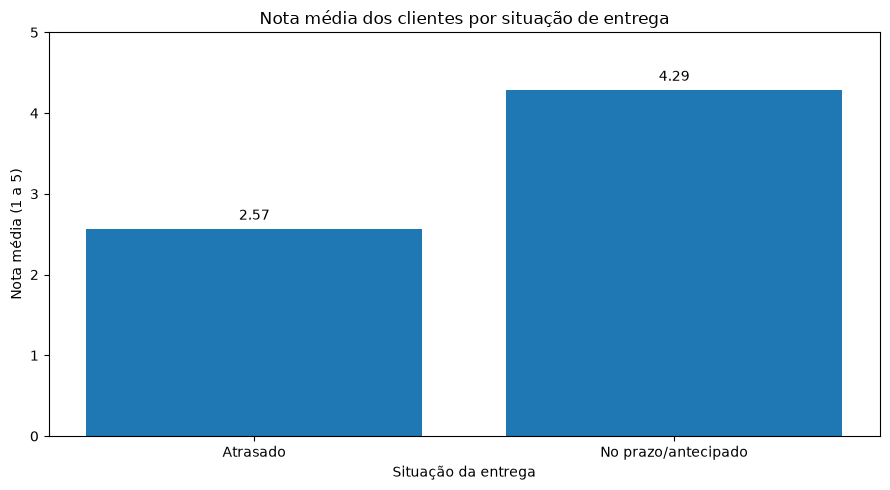

In [22]:

import matplotlib.pyplot as plt

dados_notas = resumo_atraso_notas["nota_media"]

plt.figure(figsize=(9, 5))

barras = plt.bar(
    dados_notas.index,
    dados_notas.values
)

plt.bar_label(
    barras,
    labels=[f"{valor:.2f}" for valor in dados_notas.values],
    padding=4
)

plt.title("Nota média dos clientes por situação de entrega")
plt.xlabel("Situação da entrega")
plt.ylabel("Nota média (1 a 5)")
plt.ylim(0, 5)
plt.tight_layout()
plt.show()


In [23]:

pedidos_atrasados = pedidos_com_notas[
    pedidos_com_notas["dias_atraso"] > 0
].copy()

pedidos_atrasados["faixa_atraso"] = pd.cut(
    pedidos_atrasados["dias_atraso"],
    bins=[0, 3, 7, 15, float("inf")],
    labels=[
        "1 a 3 dias",
        "4 a 7 dias",
        "8 a 15 dias",
        "Mais de 15 dias"
    ],
    include_lowest=True
)

resumo_faixas_atraso = (
    pedidos_atrasados
    .groupby("faixa_atraso", observed=False)
    .agg(
        quantidade_pedidos=("order_id", "count"),
        nota_media=("review_score", "mean"),
        percentual_notas_1_2=(
            "review_score",
            lambda notas: (notas <= 2).mean() * 100
        )
    )
    .round(2)
)

resumo_faixas_atraso


,quantidade_pedidos,nota_media,percentual_notas_1_2
faixa_atraso,,,
1 a 3 dias,2651,3.77,19.12
4 a 7 dias,1777,2.32,61.34
8 a 15 dias,1927,1.74,78.36
Mais de 15 dias,1345,1.72,78.29


### Impacto da duração do atraso nas avaliações

Os pedidos atrasados foram divididos em quatro faixas para investigar a relação entre a duração do atraso e a satisfação dos clientes.

**Principais resultados:**

- **1 a 3 dias:** nota média de 3,77 e 19,12% de avaliações negativas.
- **4 a 7 dias:** nota média de 2,32 e 61,34% de avaliações negativas.
- **8 a 15 dias:** nota média de 1,74 e 78,36% de avaliações negativas.
- **Mais de 15 dias:** nota média de 1,72 e 78,29% de avaliações negativas.

**Conclusão:** os resultados mostram uma associação entre atrasos mais longos e avaliações piores. A queda mais acentuada ocorre entre as faixas de 1 a 3 dias e 4 a 7 dias. Nas faixas superiores a 8 dias, as avaliações negativas permanecem próximas de 78%.

**Limitação:** os dados demonstram associação, não causalidade. Além disso, os resultados descrevem os pedidos que receberam avaliações e foram considerados atrasados segundo a data estimada de entrega.

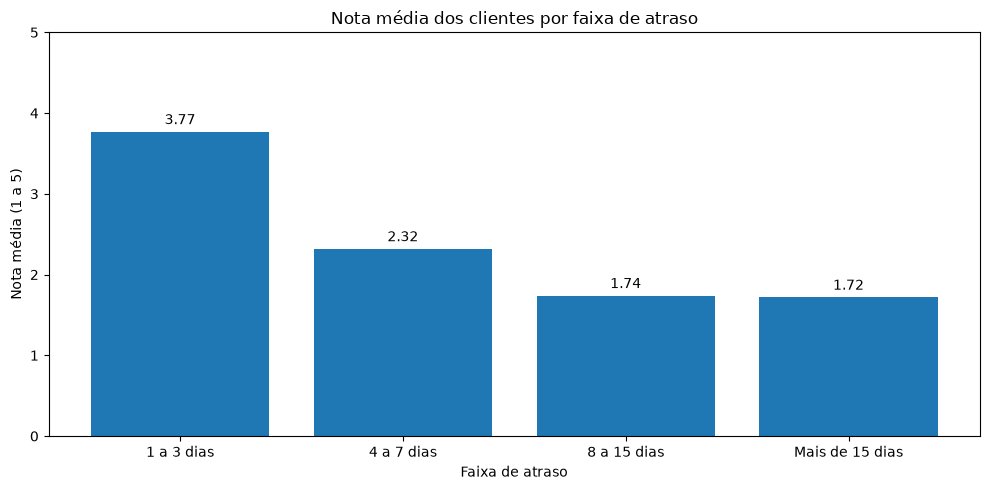

In [24]:

import matplotlib.pyplot as plt

dados_faixas = resumo_faixas_atraso["nota_media"]

plt.figure(figsize=(10, 5))

barras = plt.bar(
    dados_faixas.index.astype(str),
    dados_faixas.values
)

plt.bar_label(
    barras,
    labels=[f"{valor:.2f}" for valor in dados_faixas.values],
    padding=3
)

plt.title("Nota média dos clientes por faixa de atraso")
plt.xlabel("Faixa de atraso")
plt.ylabel("Nota média (1 a 5)")
plt.ylim(0, 5)
plt.tight_layout()
plt.show()


In [25]:

produtos = pd.read_csv(
    pasta_dados / "olist_products_dataset.csv"
)

traducao_categorias = pd.read_csv(
    pasta_dados / "product_category_name_translation.csv"
)

print("Produtos:", produtos.shape)
print("Categorias traduzidas:", traducao_categorias.shape)

produtos.head()


Produtos: (32951, 9)
Categorias traduzidas: (71, 2)


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [26]:

itens = pd.read_csv(
    pasta_dados / "olist_order_items_dataset.csv"
)

pedidos_produtos = itens.merge(
    produtos[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

pedidos_produtos_avaliacoes = pedidos_produtos.merge(
    avaliacoes[["order_id", "review_score"]],
    on="order_id",
    how="inner"
)

print("Itens de pedidos:", len(itens))
print("Itens associados a avaliações:", len(pedidos_produtos_avaliacoes))

pedidos_produtos_avaliacoes.head()


Itens de pedidos: 112650
Itens associados a avaliações: 112372


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,5
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,4
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,5
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,4
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,5


In [27]:

resumo_categorias = (
    pedidos_produtos_avaliacoes
    .dropna(subset=["product_category_name"])
    .groupby("product_category_name")
    .agg(
        quantidade_avaliacoes=("review_score", "count"),
        nota_media=("review_score", "mean"),
        percentual_negativas=(
            "review_score",
            lambda notas: (notas <= 2).mean() * 100
        )
    )
    .round(2)
    .sort_values("percentual_negativas", ascending=False)
)

resumo_categorias.head(10)


,quantidade_avaliacoes,nota_media,percentual_negativas
product_category_name,,,
seguros_e_servicos,2,2.50,50.00
pc_gamer,9,3.33,33.33
portateis_cozinha_e_preparadores_de_alimentos,15,3.27,33.33
fashion_roupa_masculina,131,3.64,28.24
moveis_escritorio,1687,3.49,26.08
casa_conforto_2,27,3.63,25.93
fraldas_higiene,39,3.26,25.64
telefonia_fixa,262,3.68,25.57
artigos_de_festas,43,3.77,23.26


In [28]:

categorias_relevantes = (
    resumo_categorias[
        resumo_categorias["quantidade_avaliacoes"] >= 100
    ]
    .sort_values("percentual_negativas", ascending=False)
)

categorias_relevantes.head(10)


,quantidade_avaliacoes,nota_media,percentual_negativas
product_category_name,,,
fashion_roupa_masculina,131,3.64,28.24
moveis_escritorio,1687,3.49,26.08
telefonia_fixa,262,3.68,25.57
audio,361,3.83,21.88
casa_conforto,435,3.83,20.23
construcao_ferramentas_seguranca,193,3.84,20.21
moveis_decoracao,8331,3.90,19.46
cama_mesa_banho,11137,3.90,18.96
informatica_acessorios,7849,3.93,18.61


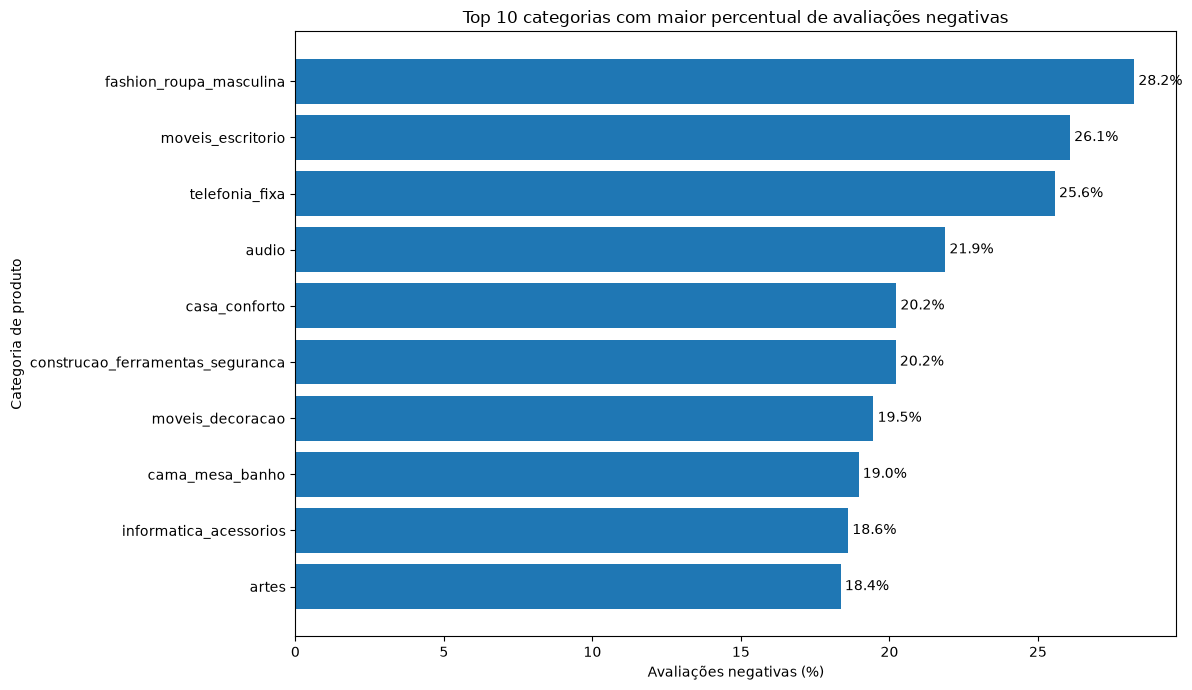

In [29]:

import matplotlib.pyplot as plt

top_categorias = categorias_relevantes.head(10).sort_values(
    "percentual_negativas"
)

plt.figure(figsize=(12, 7))

barras = plt.barh(
    top_categorias.index,
    top_categorias["percentual_negativas"]
)

plt.bar_label(
    barras,
    labels=[
        f"{valor:.1f}%"
        for valor in top_categorias["percentual_negativas"]
    ],
    padding=3
)

plt.title("Top 10 categorias com maior percentual de avaliações negativas")
plt.xlabel("Avaliações negativas (%)")
plt.ylabel("Categoria de produto")
plt.tight_layout()
plt.show()


In [30]:

categorias_relevantes_pt = categorias_relevantes.reset_index().merge(
    traducao_categorias,
    on="product_category_name",
    how="left"
)

categorias_relevantes_pt[
    [
        "product_category_name",
        "product_category_name_english",
        "quantidade_avaliacoes",
        "nota_media",
        "percentual_negativas"
    ]
].head(10)


,product_category_name,product_category_name_english,quantidade_avaliacoes,nota_media,percentual_negativas
0,fashion_roupa_masculina,fashion_male_clothing,131,3.64,28.24
1,moveis_escritorio,office_furniture,1687,3.49,26.08
2,telefonia_fixa,fixed_telephony,262,3.68,25.57
3,audio,audio,361,3.83,21.88
4,casa_conforto,home_confort,435,3.83,20.23
5,construcao_ferramentas_seguranca,construction_tools_safety,193,3.84,20.21
6,moveis_decoracao,furniture_decor,8331,3.90,19.46
7,cama_mesa_banho,bed_bath_table,11137,3.90,18.96
8,informatica_acessorios,computers_accessories,7849,3.93,18.61
9,artes,art,207,3.94,18.36


In [31]:

categorias_relevantes["quantidade_negativas"] = (
    categorias_relevantes["quantidade_avaliacoes"]
    * categorias_relevantes["percentual_negativas"]
    / 100
).round().astype(int)

categorias_relevantes.sort_values(
    "quantidade_negativas",
    ascending=False
).head(10)


,quantidade_avaliacoes,nota_media,percentual_negativas,quantidade_negativas
product_category_name,,,,
cama_mesa_banho,11137,3.90,18.96,2112
moveis_decoracao,8331,3.90,19.46,1621
informatica_acessorios,7849,3.93,18.61,1461
beleza_saude,9645,4.14,13.70,1321
esporte_lazer,8640,4.11,14.58,1260
utilidades_domesticas,6943,4.06,15.64,1086
relogios_presentes,5950,4.02,16.25,967
telefonia,4517,3.95,16.85,761
ferramentas_jardim,4329,4.04,16.08,696


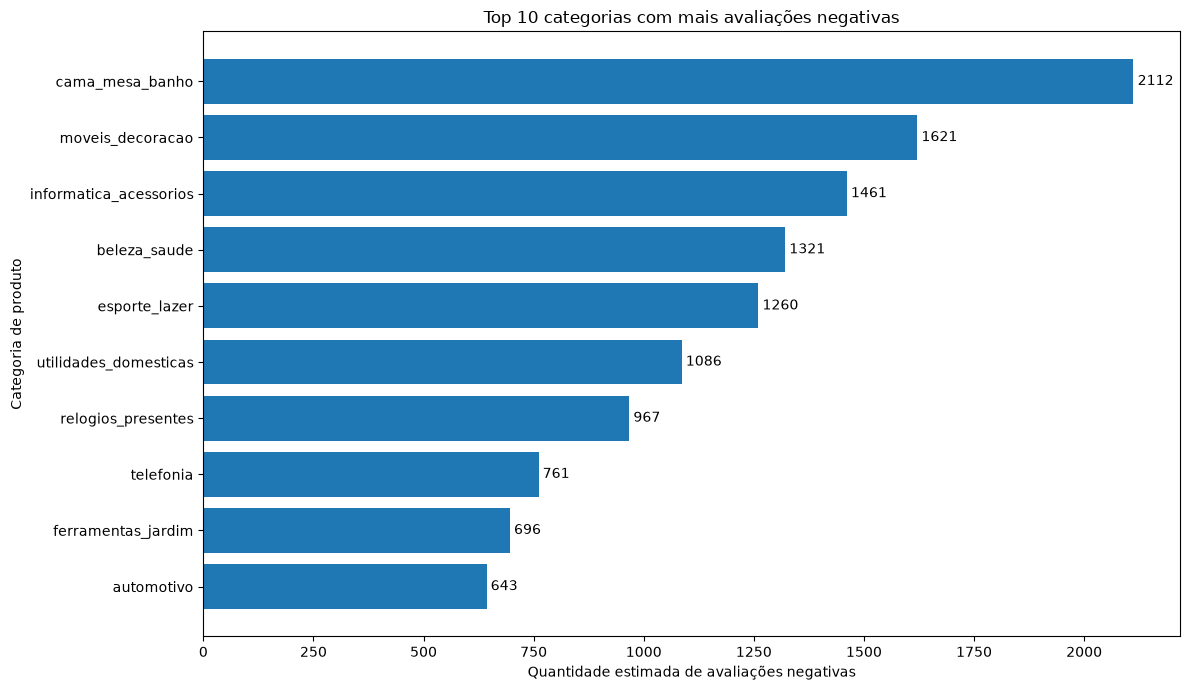

In [32]:

import matplotlib.pyplot as plt

top_negativas = categorias_relevantes.sort_values(
    "quantidade_negativas",
    ascending=True
).tail(10)

plt.figure(figsize=(12, 7))

barras = plt.barh(
    top_negativas.index,
    top_negativas["quantidade_negativas"]
)

plt.bar_label(barras, padding=3)

plt.title("Top 10 categorias com mais avaliações negativas")
plt.xlabel("Quantidade estimada de avaliações negativas")
plt.ylabel("Categoria de produto")
plt.tight_layout()
plt.show()


In [33]:

# Selecionar avaliações negativas que possuem comentários
comentarios_negativos = avaliacoes_negativas[
    avaliacoes_negativas["review_comment_message"].notna()
].copy()

# Remover comentários vazios ou contendo apenas espaços
comentarios_negativos = comentarios_negativos[
    comentarios_negativos["review_comment_message"].str.strip() != ""
]

print("Total de comentários negativos:", len(comentarios_negativos))

comentarios_negativos[
    ["order_id", "review_score", "review_comment_message"]
].head(10)


Total de comentários negativos: 10889


,order_id,review_score,review_comment_message
16,0dacf04c5ad59fd5a0cc1faa07c34e39,2,"GOSTARIA DE SABER O QUE HOUVE, SEMPRE RECEBI E..."
19,583174fbe37d3d5f0d6661be3aad1786,1,Péssimo
29,0ce9a24111d850192a933fcaab6fbad3,1,Não gostei ! Comprei gato por lebre
32,68e55ca79d04a79f20d4bfc0146f4b66,1,Sempre compro pela Internet e a entrega ocorre...
39,3c314f50bc654f3c4e317b055681dff9,1,Nada de chegar o meu pedido.
51,548df2c6e5f089574614894bca78acf5,1,recebi somente 1 controle Midea Split ESTILO.\...
68,97d2f8fe76f2f253b8291e17b5383884,1,O produto não chegou no prazo estipulado e cau...
76,9ac05114800f02bfaa783bd76842dbe2,1,"Produto muito inferior, mal acabado."
89,a2714ecbf6eeb3bb9cd7dba6dc1c5e82,1,Pedi reembolso e sem resposta até momento
115,45c780334bc32cb77559a65c5f171160,1,Este foi o pedido\r\nBalde Com 128 Peças - Blo...


In [34]:

import re

comentarios = comentarios_negativos["review_comment_message"].str.lower()

motivos = {
    "Entrega": r"\b(entrega|entregue|atraso|atrasado|prazo|chegou|chegar|recebi|receber|correios|transportadora)\b",
    "Qualidade do produto": r"\b(qualidade|defeito|quebrado|danificado|inferior|péssimo|pessima|ruim|estragado|funciona|funcionando)\b",
    "Produto diferente ou incompleto": r"\b(diferente|errado|faltando|faltou|incompleto|incompleta|trocar|troca)\b",
    "Reembolso e atendimento": r"\b(reembolso|reembolsar|devolução|devolucao|dinheiro|atendimento|resposta|responder|contato)\b"
}

resultados_motivos = []

for motivo, padrao in motivos.items():
    quantidade = comentarios.str.contains(
        padrao,
        regex=True,
        na=False
    ).sum()

    resultados_motivos.append({
        "motivo": motivo,
        "quantidade_comentarios": quantidade
    })

resumo_motivos = (
    __import__("pandas")
    .DataFrame(resultados_motivos)
    .sort_values("quantidade_comentarios", ascending=False)
)

resumo_motivos


C:\Users\João Vitor\AppData\Local\Temp\ipykernel_26380\442717992.py:15: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  quantidade = comentarios.str.contains(


,motivo,quantidade_comentarios
0,Entrega,6415
3,Reembolso e atendimento,1362
1,Qualidade do produto,1237
2,Produto diferente ou incompleto,1210


In [35]:

# Relacionar avaliações negativas aos pedidos e produtos
comentarios_por_categoria = comentarios_negativos[
    ["order_id", "review_comment_message"]
].merge(
    pedidos_produtos[["order_id", "product_category_name"]].drop_duplicates(),
    on="order_id",
    how="inner"
)

# Identificar comentários que mencionam problemas de entrega
padrao_entrega = (
    r"\b(?:entrega|entregue|atraso|atrasado|prazo|"
    r"chegou|chegar|recebi|receber|correios|transportadora)\b"
)

comentarios_por_categoria["menciona_entrega"] = (
    comentarios_por_categoria["review_comment_message"]
    .str.lower()
    .str.contains(padrao_entrega, regex=True, na=False)
)

print("Total de registros:", len(comentarios_por_categoria))
print(
    "Registros que mencionam entrega:",
    comentarios_por_categoria["menciona_entrega"].sum()
)

comentarios_por_categoria.head()


Total de registros: 10727
Registros que mencionam entrega: 6405


,order_id,review_comment_message,product_category_name,menciona_entrega
0,0dacf04c5ad59fd5a0cc1faa07c34e39,"GOSTARIA DE SABER O QUE HOUVE, SEMPRE RECEBI E...",cool_stuff,True
1,583174fbe37d3d5f0d6661be3aad1786,Péssimo,malas_acessorios,False
2,0ce9a24111d850192a933fcaab6fbad3,Não gostei ! Comprei gato por lebre,cama_mesa_banho,False
3,68e55ca79d04a79f20d4bfc0146f4b66,Sempre compro pela Internet e a entrega ocorre...,relogios_presentes,True
4,3c314f50bc654f3c4e317b055681dff9,Nada de chegar o meu pedido.,cama_mesa_banho,True


In [36]:

resumo_entrega_categorias = (
    comentarios_por_categoria
    .dropna(subset=["product_category_name"])
    .groupby("product_category_name")
    .agg(
        total_comentarios=("order_id", "count"),
        comentarios_entrega=("menciona_entrega", "sum")
    )
)

resumo_entrega_categorias["percentual_entrega"] = (
    resumo_entrega_categorias["comentarios_entrega"]
    / resumo_entrega_categorias["total_comentarios"]
    * 100
)

resumo_entrega_categorias = (
    resumo_entrega_categorias[
        resumo_entrega_categorias["total_comentarios"] >= 100
    ]
    .sort_values("comentarios_entrega", ascending=False)
    .head(10)
    .round(2)
)

resumo_entrega_categorias


,total_comentarios,comentarios_entrega,percentual_entrega
product_category_name,,,
cama_mesa_banho,1193,672,56.33
beleza_saude,815,510,62.58
esporte_lazer,758,488,64.38
informatica_acessorios,835,483,57.84
moveis_decoracao,780,456,58.46
utilidades_domesticas,585,364,62.22
relogios_presentes,649,355,54.70
telefonia,490,261,53.27
automotivo,439,260,59.23


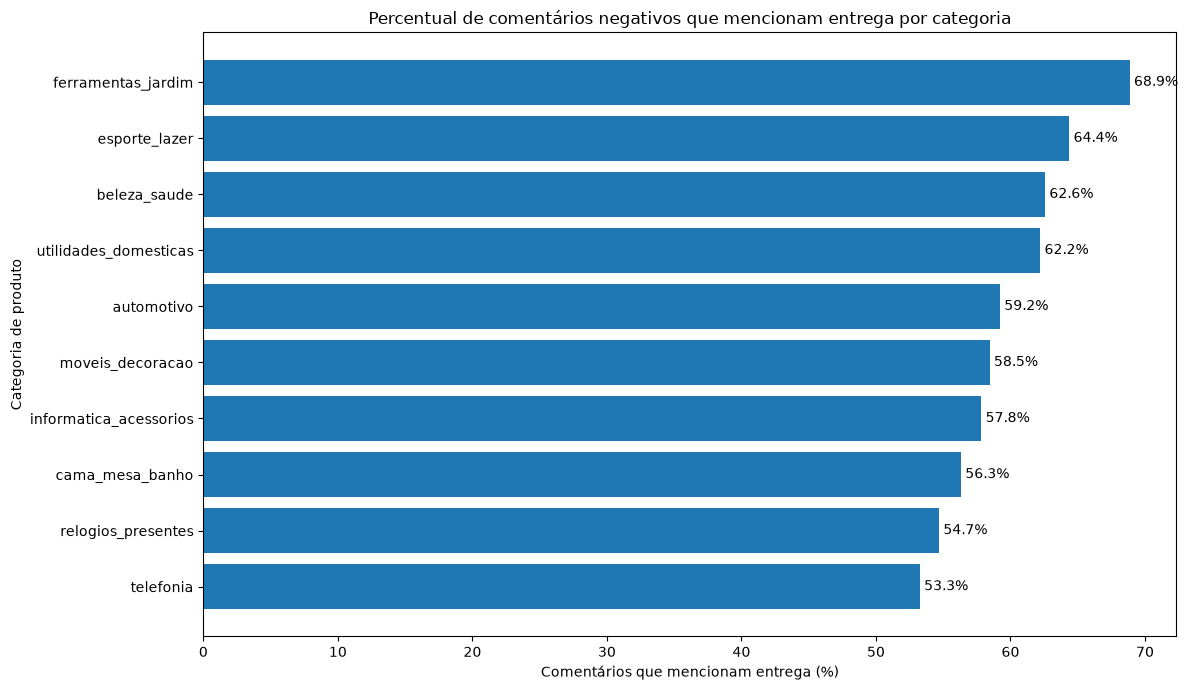

In [37]:

import matplotlib.pyplot as plt

grafico_entrega = resumo_entrega_categorias.sort_values(
    "percentual_entrega"
)

plt.figure(figsize=(12, 7))

barras = plt.barh(
    grafico_entrega.index,
    grafico_entrega["percentual_entrega"]
)

plt.bar_label(
    barras,
    labels=[
        f"{valor:.1f}%"
        for valor in grafico_entrega["percentual_entrega"]
    ],
    padding=3
)

plt.title(
    "Percentual de comentários negativos que mencionam entrega por categoria"
)
plt.xlabel("Comentários que mencionam entrega (%)")
plt.ylabel("Categoria de produto")
plt.tight_layout()
plt.show()


In [38]:

caminho_resultado = pasta_projeto / "data" / "processed" / "reclamacoes_entrega_por_categoria.csv"

resumo_entrega_categorias.to_csv(
    caminho_resultado,
    encoding="utf-8-sig"
)

print("Arquivo salvo em:", caminho_resultado)


NameError: name 'pasta_projeto' is not defined

In [39]:

from pathlib import Path

pasta_projeto = Path.cwd()

pasta_processados = pasta_projeto / "data" / "processed"
pasta_processados.mkdir(parents=True, exist_ok=True)

caminho_resultado = pasta_processados / "reclamacoes_entrega_por_categoria.csv"

resumo_entrega_categorias.to_csv(
    caminho_resultado,
    encoding="utf-8-sig"
)

print("Arquivo salvo em:", caminho_resultado.resolve())


Arquivo salvo em: C:\Users\João Vitor\Documents\olist-ecommerce-analytics\notebooks\data\processed\reclamacoes_entrega_por_categoria.csv


In [40]:

from pathlib import Path

pasta_projeto = Path.cwd().parent

pasta_processados = pasta_projeto / "data" / "processed"
pasta_processados.mkdir(parents=True, exist_ok=True)

caminho_resultado = pasta_processados / "reclamacoes_entrega_por_categoria.csv"

resumo_entrega_categorias.to_csv(
    caminho_resultado,
    encoding="utf-8-sig"
)

print("Arquivo salvo em:", caminho_resultado.resolve())


Arquivo salvo em: C:\Users\João Vitor\Documents\olist-ecommerce-analytics\data\processed\reclamacoes_entrega_por_categoria.csv


In [41]:

# Usar pedidos entregues que possuem as datas necessárias
analise_mensal = pedidos_entregues.dropna(
    subset=[
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
).copy()

analise_mensal["order_purchase_timestamp"] = pd.to_datetime(
    analise_mensal["order_purchase_timestamp"]
)

analise_mensal["dias_atraso"] = (
    analise_mensal["order_delivered_customer_date"]
    - analise_mensal["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

analise_mensal["mes_compra"] = (
    analise_mensal["order_purchase_timestamp"].dt.to_period("M")
)

resumo_mensal = (
    analise_mensal.groupby("mes_compra")
    .agg(
        total_pedidos=("order_id", "count"),
        pedidos_atrasados=("dias_atraso", lambda x: (x > 0).sum()),
        atraso_medio_dias=(
            "dias_atraso",
            lambda x: x[x > 0].mean()
        )
    )
)

resumo_mensal["percentual_atraso"] = (
    resumo_mensal["pedidos_atrasados"]
    / resumo_mensal["total_pedidos"]
    * 100
)

resumo_mensal.round(2).tail(10)


,total_pedidos,pedidos_atrasados,atraso_medio_dias,percentual_atraso
mes_compra,,,,
2017-11,7288,1043,10.39,14.31
2017-12,5513,462,9.36,8.38
2018-01,7069,464,11.02,6.56
2018-02,6555,1048,11.82,15.99
2018-03,7003,1496,9.58,21.36
2018-04,6798,361,9.51,5.31
2018-05,6749,556,6.36,8.24
2018-06,6096,83,12.14,1.36
2018-07,6156,276,7.00,4.48


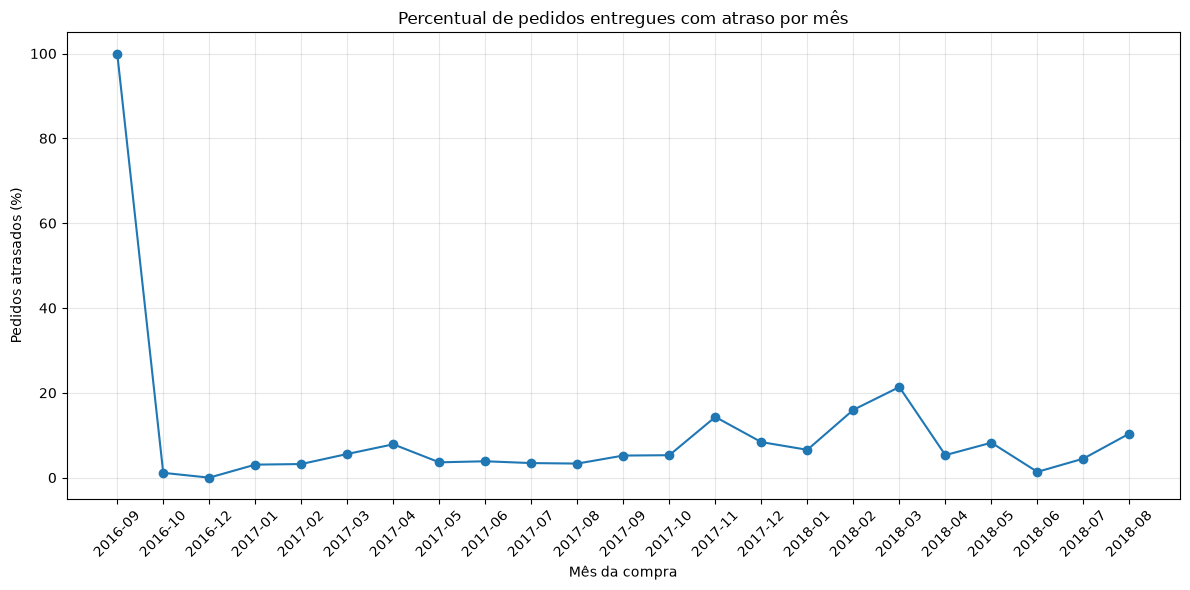

In [42]:

import matplotlib.pyplot as plt

dados_grafico = resumo_mensal.copy()
dados_grafico.index = dados_grafico.index.astype(str)

plt.figure(figsize=(12, 6))

plt.plot(
    dados_grafico.index,
    dados_grafico["percentual_atraso"],
    marker="o"
)

plt.title("Percentual de pedidos entregues com atraso por mês")
plt.xlabel("Mês da compra")
plt.ylabel("Pedidos atrasados (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [43]:

caminho_mensal = pasta_processados / "atrasos_por_mes.csv"

resumo_mensal.to_csv(
    caminho_mensal,
    encoding="utf-8-sig"
)

print("Arquivo salvo em:", caminho_mensal.resolve())


Arquivo salvo em: C:\Users\João Vitor\Documents\olist-ecommerce-analytics\data\processed\atrasos_por_mes.csv



## Análise mensal dos atrasos nas entregas

### Objetivo
Investigar como o percentual de pedidos entregues após a data estimada varia ao longo dos meses.

### Principais resultados
- Março de 2018 apresentou o maior percentual de atrasos entre os meses analisados: 21,36%.
- Junho de 2018 apresentou o menor percentual de atrasos: 1,36%.
- O maior atraso médio entre os pedidos atrasados ocorreu em junho de 2018: 12,14 dias.
- A frequência dos atrasos e a duração média dos atrasos representam indicadores diferentes e devem ser analisados em conjunto.

### Relevância para o negócio
O acompanhamento mensal permite identificar períodos que merecem investigação e apoiar decisões para melhorar o planejamento logístico e a experiência do cliente.

### Limitações
A análise considera pedidos entregues com datas disponíveis e utiliza o mês da compra como referência. Os resultados mostram associações temporais, mas não identificam as causas dos atrasos.


In [44]:

from pathlib import Path

pasta_processados = Path.cwd().parent / "data" / "processed"

print("Pasta:", pasta_processados.resolve())
print("\nArquivos encontrados:")

for arquivo in sorted(pasta_processados.iterdir()):
    if arquivo.is_file():
        print(f"- {arquivo.name}")


Pasta: C:\Users\João Vitor\Documents\olist-ecommerce-analytics\data\processed

Arquivos encontrados:
- atrasos_por_mes.csv
- reclamacoes_entrega_por_categoria.csv


In [45]:

caminho_estados = pasta_processados / "atrasos_por_estado.csv"

atrasos_por_estado.to_csv(
    caminho_estados,
    encoding="utf-8-sig"
)

print("Arquivo salvo em:", caminho_estados.resolve())
print("\nPrévia da tabela:")
display(atrasos_por_estado.head())


NameError: name 'atrasos_por_estado' is not defined

In [46]:

atrasos_por_estado = (
    pedidos_com_estado
    .dropna(subset=["order_delivered_customer_date",
                    "order_estimated_delivery_date"])
    .assign(
        dias_atraso=lambda df: (
            pd.to_datetime(df["order_delivered_customer_date"])
            - pd.to_datetime(df["order_estimated_delivery_date"])
        ).dt.total_seconds() / 86400
    )
    .groupby("customer_state")
    .agg(
        pedidos_com_data=("order_id", "count"),
        pedidos_atrasados=("dias_atraso", lambda x: (x > 0).sum())
    )
)

atrasos_por_estado["percentual_atraso"] = (
    atrasos_por_estado["pedidos_atrasados"]
    / atrasos_por_estado["pedidos_com_data"]
    * 100
)

atrasos_por_estado = atrasos_por_estado.sort_values(
    "percentual_atraso", ascending=False
).round(2)

display(atrasos_por_estado.head())


NameError: name 'pedidos_com_estado' is not defined

In [47]:

import pandas as pd
from pathlib import Path

pasta_projeto = Path.cwd().parent
pasta_dados = pasta_projeto / "data" / "raw"

pedidos = pd.read_csv(pasta_dados / "olist_orders_dataset.csv")
clientes = pd.read_csv(pasta_dados / "olist_customers_dataset.csv")

pedidos_com_estado = pedidos.merge(
    clientes[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)

print("Total de pedidos:", len(pedidos_com_estado))
print("Estados ausentes:", pedidos_com_estado["customer_state"].isna().sum())

display(
    pedidos_com_estado[
        ["order_id", "customer_state", "order_status"]
    ].head()
)


Total de pedidos: 99441
Estados ausentes: 0


,order_id,customer_state,order_status
0,e481f51cbdc54678b7cc49136f2d6af7,SP,delivered
1,53cdb2fc8bc7dce0b6741e2150273451,BA,delivered
2,47770eb9100c2d0c44946d9cf07ec65d,GO,delivered
3,949d5b44dbf5de918fe9c16f97b45f8a,RN,delivered
4,ad21c59c0840e6cb83a9ceb5573f8159,SP,delivered


In [48]:

pedidos_com_estado["order_delivered_customer_date"] = pd.to_datetime(
    pedidos_com_estado["order_delivered_customer_date"]
)

pedidos_com_estado["order_estimated_delivery_date"] = pd.to_datetime(
    pedidos_com_estado["order_estimated_delivery_date"]
)

pedidos_com_estado["dias_atraso"] = (
    pedidos_com_estado["order_delivered_customer_date"]
    - pedidos_com_estado["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

base_com_data = pedidos_com_estado.dropna(
    subset=[
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

atrasos_por_estado = (
    base_com_data.groupby("customer_state")
    .agg(
        pedidos_com_data=("order_id", "count"),
        pedidos_atrasados=("dias_atraso", lambda x: (x > 0).sum())
    )
)

atrasos_por_estado["percentual_atraso"] = (
    atrasos_por_estado["pedidos_atrasados"]
    / atrasos_por_estado["pedidos_com_data"]
    * 100
)

atrasos_por_estado = atrasos_por_estado.sort_values(
    "percentual_atraso", ascending=False
).round(2)

caminho_estados = pasta_processados / "atrasos_por_estado.csv"

atrasos_por_estado.to_csv(caminho_estados, encoding="utf-8-sig")

print("Arquivo salvo em:", caminho_estados.resolve())
display(atrasos_por_estado.head(10))


Arquivo salvo em: C:\Users\João Vitor\Documents\olist-ecommerce-analytics\data\processed\atrasos_por_estado.csv


,pedidos_com_data,pedidos_atrasados,percentual_atraso
customer_state,,,
AL,397,95,23.93
MA,717,141,19.67
PI,476,76,15.97
CE,1279,196,15.32
SE,335,51,15.22
BA,3256,457,14.04
RJ,12353,1664,13.47
TO,274,35,12.77
PA,946,117,12.37


In [49]:

print("Arquivos disponíveis em data/processed:\n")

for arquivo in sorted(pasta_processados.glob("*.csv")):
    print(f"{arquivo.name} — {arquivo.stat().st_size / 1024:.1f} KB")



Arquivos disponíveis em data/processed:

atrasos_por_estado.csv — 0.5 KB
atrasos_por_mes.csv — 1.3 KB
reclamacoes_entrega_por_categoria.csv — 0.4 KB


In [50]:

import sqlite3

conexao = sqlite3.connect(":memory:")

resultado = conexao.execute(
    "SELECT sqlite_version()"
).fetchone()

print("SQLite instalado e funcionando!")
print("Versão:", resultado[0])

conexao.close()


SQLite instalado e funcionando!
Versão: 3.50.4


In [51]:

import sqlite3
from pathlib import Path

caminho_banco = pasta_processados / "olist_analytics.db"

conexao = sqlite3.connect(caminho_banco)

print("Banco de dados criado/conectado em:")
print(caminho_banco.resolve())

conexao.close()


Banco de dados criado/conectado em:
C:\Users\João Vitor\Documents\olist-ecommerce-analytics\data\processed\olist_analytics.db


In [52]:

import pandas as pd
import sqlite3

caminho_pedidos = pasta_dados / "olist_orders_dataset.csv"

pedidos_sql = pd.read_csv(caminho_pedidos)

conexao = sqlite3.connect(caminho_banco)

pedidos_sql.to_sql(
    "pedidos",
    conexao,
    if_exists="replace",
    index=False
)

quantidade = conexao.execute(
    "SELECT COUNT(*) FROM pedidos"
).fetchone()[0]

print("Tabela 'pedidos' criada com sucesso!")
print("Quantidade de registros:", quantidade)

conexao.close()


Tabela 'pedidos' criada com sucesso!
Quantidade de registros: 99441


In [53]:

conexao = sqlite3.connect(caminho_banco)

consulta = """
SELECT
    order_status,
    COUNT(*) AS quantidade_pedidos
FROM pedidos
GROUP BY order_status
ORDER BY quantidade_pedidos DESC;
"""

resultado_sql = pd.read_sql_query(consulta, conexao)

conexao.close()

display(resultado_sql)


,order_status,quantidade_pedidos
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


In [54]:

conexao = sqlite3.connect(caminho_banco)

consulta = """
SELECT
    COUNT(*) AS total_pedidos,
    SUM(CASE WHEN order_status = 'canceled' THEN 1 ELSE 0 END)
        AS pedidos_cancelados,
    ROUND(
        100.0 * SUM(
            CASE WHEN order_status = 'canceled' THEN 1 ELSE 0 END
        ) / COUNT(*),
        2
    ) AS percentual_cancelamento
FROM pedidos;
"""

resultado_sql = pd.read_sql_query(consulta, conexao)

conexao.close()

display(resultado_sql)


,total_pedidos,pedidos_cancelados,percentual_cancelamento
0,99441,625,0.63


In [55]:

conexao = sqlite3.connect(caminho_banco)

consulta = """
SELECT
    SUBSTR(order_purchase_timestamp, 1, 7) AS mes_compra,
    COUNT(*) AS quantidade_pedidos
FROM pedidos
WHERE order_purchase_timestamp IS NOT NULL
GROUP BY SUBSTR(order_purchase_timestamp, 1, 7)
ORDER BY mes_compra;
"""

resultado_sql = pd.read_sql_query(consulta, conexao)

conexao.close()

display(resultado_sql.tail(10))


,mes_compra,quantidade_pedidos
15,2018-01,7269
16,2018-02,6728
17,2018-03,7211
18,2018-04,6939
19,2018-05,6873
20,2018-06,6167
21,2018-07,6292
22,2018-08,6512
23,2018-09,16
24,2018-10,4


In [56]:

clientes_sql = pd.read_csv(
    pasta_dados / "olist_customers_dataset.csv"
)

conexao = sqlite3.connect(caminho_banco)

clientes_sql.to_sql(
    "clientes",
    conexao,
    if_exists="replace",
    index=False
)

consulta = """
SELECT
    c.customer_state AS estado,
    COUNT(*) AS quantidade_pedidos
FROM pedidos AS p
INNER JOIN clientes AS c
    ON p.customer_id = c.customer_id
GROUP BY c.customer_state
ORDER BY quantidade_pedidos DESC
LIMIT 10;
"""

resultado_sql = pd.read_sql_query(consulta, conexao)

conexao.close()

display(resultado_sql)


,estado,quantidade_pedidos
0,SP,41746
1,RJ,12852
2,MG,11635
3,RS,5466
4,PR,5045
5,SC,3637
6,BA,3380
7,DF,2140
8,ES,2033
9,GO,2020


In [57]:

pagamentos_sql = pd.read_csv(
    pasta_dados / "olist_order_payments_dataset.csv"
)

conexao = sqlite3.connect(caminho_banco)

pagamentos_sql.to_sql(
    "pagamentos",
    conexao,
    if_exists="replace",
    index=False
)

consulta = """
SELECT
    c.customer_state AS estado,
    ROUND(SUM(pg.payment_value), 2) AS valor_total_pagamentos,
    COUNT(DISTINCT p.order_id) AS quantidade_pedidos
FROM pedidos AS p
INNER JOIN clientes AS c
    ON p.customer_id = c.customer_id
INNER JOIN pagamentos AS pg
    ON p.order_id = pg.order_id
GROUP BY c.customer_state
ORDER BY valor_total_pagamentos DESC
LIMIT 10;
"""

resultado_sql = pd.read_sql_query(consulta, conexao)

conexao.close()

display(resultado_sql)


,estado,valor_total_pagamentos,quantidade_pedidos
0,SP,5998226.96,41745
1,RJ,2144379.69,12852
2,MG,1872257.26,11635
3,RS,890898.54,5466
4,PR,811156.38,5045
5,SC,623086.43,3637
6,BA,616645.82,3380
7,DF,355141.08,2140
8,GO,350092.31,2020
9,ES,325967.55,2033


In [58]:

conexao = sqlite3.connect(caminho_banco)

consulta = """
SELECT
    c.customer_state AS estado,
    ROUND(SUM(pg.payment_value), 2) AS valor_total_pagamentos,
    COUNT(DISTINCT p.order_id) AS quantidade_pedidos,
    ROUND(
        SUM(pg.payment_value) /
        COUNT(DISTINCT p.order_id),
        2
    ) AS ticket_medio
FROM pedidos AS p
INNER JOIN clientes AS c
    ON p.customer_id = c.customer_id
INNER JOIN pagamentos AS pg
    ON p.order_id = pg.order_id
GROUP BY c.customer_state
ORDER BY ticket_medio DESC
LIMIT 10;
"""

resultado_sql = pd.read_sql_query(consulta, conexao)

conexao.close()

display(resultado_sql)


,estado,valor_total_pagamentos,quantidade_pedidos,ticket_medio
0,PB,141545.72,536,264.08
1,AC,19680.62,81,242.97
2,RO,60866.20,253,240.58
3,AP,16262.80,68,239.16
4,AL,96962.06,413,234.77
5,PA,218295.85,975,223.89
6,TO,61485.33,280,219.59
7,PI,108523.97,495,219.24
8,RR,10064.62,46,218.80
9,SE,75246.25,350,214.99


In [59]:

conexao = sqlite3.connect(caminho_banco)

consulta = """
SELECT
    c.customer_state AS estado,
    ROUND(
        SUM(pg.payment_value) /
        COUNT(DISTINCT p.order_id),
        2
    ) AS ticket_medio,
    COUNT(DISTINCT p.order_id) AS quantidade_pedidos
FROM pedidos AS p
INNER JOIN clientes AS c
    ON p.customer_id = c.customer_id
INNER JOIN pagamentos AS pg
    ON p.order_id = pg.order_id
GROUP BY c.customer_state
HAVING COUNT(DISTINCT p.order_id) >= 100
ORDER BY ticket_medio DESC;
"""

resultado_sql = pd.read_sql_query(consulta, conexao)

conexao.close()

display(resultado_sql)


,estado,ticket_medio,quantidade_pedidos
0,PB,264.08,536
1,RO,240.58,253
2,AL,234.77,413
3,PA,223.89,975
4,TO,219.59,280
5,PI,219.24,495
6,SE,214.99,350
7,RN,211.79,485
8,CE,209.18,1336
9,MT,206.21,907


In [60]:

caminho_ticket = pasta_processados / "ticket_medio_por_estado.csv"

resultado_sql.to_csv(
    caminho_ticket,
    index=False,
    encoding="utf-8-sig"
)

print("Arquivo salvo em:", caminho_ticket.resolve())


Arquivo salvo em: C:\Users\João Vitor\Documents\olist-ecommerce-analytics\data\processed\ticket_medio_por_estado.csv


In [61]:

conexao = sqlite3.connect(caminho_banco)

consulta = """
SELECT
    payment_type AS metodo_pagamento,
    COUNT(*) AS quantidade_registros,
    ROUND(SUM(payment_value), 2) AS valor_total,
    ROUND(AVG(payment_value), 2) AS valor_medio_registro
FROM pagamentos
GROUP BY payment_type
ORDER BY valor_total DESC;
"""

resultado_pagamentos_sql = pd.read_sql_query(consulta, conexao)

conexao.close()

display(resultado_pagamentos_sql)


,metodo_pagamento,quantidade_registros,valor_total,valor_medio_registro
0,credit_card,76795,12542084.19,163.32
1,boleto,19784,2869361.27,145.03
2,voucher,5775,379436.87,65.70
3,debit_card,1529,217989.79,142.57
4,not_defined,3,0.00,0.00


In [62]:

caminho_metodos = pasta_processados / "analise_metodos_pagamento.csv"

resultado_pagamentos_sql.to_csv(
    caminho_metodos,
    index=False,
    encoding="utf-8-sig"
)

print("Arquivo salvo em:", caminho_metodos.resolve())



Arquivo salvo em: C:\Users\João Vitor\Documents\olist-ecommerce-analytics\data\processed\analise_metodos_pagamento.csv


In [63]:

print("Arquivo existe:", caminho_metodos.exists())
print("Caminho:", caminho_metodos.resolve())


Arquivo existe: True
Caminho: C:\Users\João Vitor\Documents\olist-ecommerce-analytics\data\processed\analise_metodos_pagamento.csv


In [64]:

conexao = sqlite3.connect(caminho_banco)

consulta = """
SELECT
    COUNT(*) AS total_pedidos,
    SUM(CASE WHEN order_status = 'delivered' THEN 1 ELSE 0 END)
        AS pedidos_entregues,
    SUM(CASE WHEN order_status = 'canceled' THEN 1 ELSE 0 END)
        AS pedidos_cancelados,
    ROUND(
        100.0 * SUM(
            CASE WHEN order_status = 'delivered' THEN 1 ELSE 0 END
        ) / COUNT(*),
        2
    ) AS percentual_entregues
FROM pedidos;
"""

indicadores_gerais = pd.read_sql_query(consulta, conexao)

conexao.close()

display(indicadores_gerais)


,total_pedidos,pedidos_entregues,pedidos_cancelados,percentual_entregues
0,99441,96478,625,97.02


In [65]:
total_pedidos	pedidos_entregues	pedidos_cancelados	percentual_entregues
0	99441	96478	625	97.02


SyntaxError: invalid syntax (856635197.py, line 1)

In [66]:

caminho_indicadores = pasta_processados / "indicadores_gerais.csv"

indicadores_gerais.to_csv(
    caminho_indicadores,
    index=False,
    encoding="utf-8-sig"
)

print("Arquivo salvo em:", caminho_indicadores.resolve())


Arquivo salvo em: C:\Users\João Vitor\Documents\olist-ecommerce-analytics\data\processed\indicadores_gerais.csv


In [67]:

print("Arquivos preparados para o Power BI:\n")

for arquivo in sorted(pasta_processados.glob("*.csv")):
    print(f"✅ {arquivo.name}")



Arquivos preparados para o Power BI:

✅ analise_metodos_pagamento.csv
✅ atrasos_por_estado.csv
✅ atrasos_por_mes.csv
✅ indicadores_gerais.csv
✅ reclamacoes_entrega_por_categoria.csv
✅ ticket_medio_por_estado.csv
